In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')
    
from pathlib import Path
import polars as pl
from matplotlib import pyplot as plt
import numpy as np

# Training data

## Dataset

In [2]:
plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')
df_training_set = pl.read_csv(plato_data_directory / 'training_df_try3.csv')
df_training_set.head()

path,DR3,tic,Sector,label,remove,freq_max,power_max,Teff
str,i64,i64,str,str,str,f64,f64,f64
"""/STER/mamsie/tess/TIC/tglc_scr…",2141241175031331712,377296128,"""s0023""","""INSTRUMENT/JUNK""",null,1.522936,0.018504,5659.009
"""/STER/mamsie/tess/TIC/tglc_scr…",2140291093905900800,243301088,"""s0023""","""DSCT_BCEP""",null,12.748666,0.701801,null
"""/STER/mamsie/tess/TIC/tglc_scr…",2142716169880275712,243276000,"""s0023""","""INSTRUMENT/JUNK""",null,0.836113,0.023235,5292.7217
"""/STER/mamsie/tess/TIC/tglc_scr…",2158346754163939456,233156947,"""s0023""","""DSCT_BCEP""",null,14.393021,0.326834,6826.2925
"""/STER/mamsie/tess/TIC/tglc_scr…",2158341432700247680,233161073,"""s0023""","""DSCT_BCEP""",null,8.176955,0.500122,null


In [3]:
# Unique paths and unique tics
df_training_set.height, df_training_set.unique('path').height, df_training_set.unique('tic').height

(27016, 26979, 6117)

In [4]:
# Remove duplicates
df_training_set = df_training_set.unique('path')

In [5]:
# Make training set compatible with inference parquets
df_training_set.rename({'path': 'FilePath'}).write_parquet(plato_data_directory / 'training_df_try3.parquet')

In [6]:
# Sources per class
df_training_set.group_by('label').len().sort('label')

label,len
str,u32
"""APERIODIC""",1522
"""CONTACT_ROT""",3596
"""DSCT_BCEP""",6797
"""ECLIPSE""",1332
"""GDOR_SPB""",4325
"""INSTRUMENT/JUNK""",5715
"""RRLYR_CEPH""",1108
"""SOLARLIKE""",2584


In [7]:
# sanity check
df_training_set['path'].is_duplicated().sum()

0

## Features

In [8]:
# Loading features
df_training_features = pl.read_parquet('../results/training_set/')
print(df_training_features.height)
df_training_features = df_training_features.drop_nans().drop_nulls()
print(df_training_features.height)
df_training_features = df_training_features.join(df_training_set.select(['path', 'label', 'tic']), on='path')
print(df_training_features.height)

26959
26959
26959


In [10]:
# Average values per class
df_training_features.drop(['tic', 'path']).group_by('label').mean()

label,flux_std,flux_skewness,flux_kurtosis,flux_iqr,flux_amplitude,flux_mad,flux_largest_departure,flux_percent_difference,flux_ratio_mid20,flux_ratio_mid45,flux_ratio_mid50,flux_ratio_mid65,flux_ratio_mid80,max_slope,ls_fundamental_log_10_frequency,ls_fundamental_log_10_fap,fourier_amplitude_1,fourier_amplitude_2,fourier_amplitude_3,fourier_amplitude_4,fourier_relative_phase_2,fourier_relative_phase_3,fourier_relative_phase_4,fourier_r2_fit
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""INSTRUMENT/JUNK""",0.005279,-0.017244,4.175844,0.004617,0.007887,0.002289,0.029988,0.01579,0.132208,0.238351,0.35796,0.505988,0.728484,0.682777,-0.32111,-19.991696,0.003678,0.002263,0.001677,0.001041,-0.287427,-0.019564,0.074862,0.156527
"""APERIODIC""",0.000896,-0.305238,3.260914,0.000902,0.001374,0.000448,0.004618,0.002748,0.131744,0.237598,0.357579,0.506173,0.7277,0.166665,-0.686446,-15.057455,0.000471,0.000303,0.000214,0.00014,-0.212351,-0.151542,-0.00804,0.113734
"""RRLYR_CEPH""",0.179973,0.336642,-0.546037,0.298279,0.271733,0.129595,0.510994,0.570659,0.24054,0.405178,0.555103,0.704655,0.871369,12.48919,0.24765,-261.129181,0.221548,0.082102,0.049901,0.030054,0.038627,-0.034753,-0.063625,0.900199
"""GDOR_SPB""",0.004666,-0.022585,1.426989,0.005904,0.007544,0.002926,0.018821,0.01534,0.151182,0.270863,0.403515,0.560931,0.772524,0.291569,0.140742,-98.21398,0.00408,0.000525,0.000246,0.000156,-0.043167,0.023406,-0.005931,0.337998
"""ECLIPSE""",0.046132,-3.106377,15.384735,0.016698,0.067438,0.007026,0.243172,0.139997,0.065893,0.120514,0.186456,0.287332,0.515719,3.243445,-0.116847,-64.41329,0.034464,0.024884,0.019871,0.014327,-0.019782,0.062777,0.065427,0.472718
"""SOLARLIKE""",0.002961,-0.378813,2.915993,0.002413,0.00422,0.001185,0.018832,0.008477,0.141565,0.254774,0.381484,0.535147,0.751643,0.548177,-0.076834,-13.344373,0.001927,0.00109,0.000744,0.000507,-0.108097,-0.03015,0.02289,0.091474
"""DSCT_BCEP""",0.007055,-0.10521,1.003196,0.009094,0.011028,0.004518,0.029666,0.022316,0.159781,0.284227,0.418817,0.574909,0.781708,1.229071,0.998812,-92.051181,0.035319,0.01553,0.031885,0.01495,-0.010646,0.006015,0.002154,0.321394
"""CONTACT_ROT""",0.030309,-0.139076,1.10477,0.050395,0.045173,0.02314,0.087286,0.092143,0.188856,0.330124,0.47372,0.628992,0.817756,1.746017,0.042778,-182.187157,0.038617,0.006503,0.002694,0.001177,-0.016251,-0.026049,-0.016007,0.588188


In [11]:
# Log transforms for features with large dynamic range

log_columns = [
    'fourier_amplitude_1', 'fourier_amplitude_2', 'fourier_amplitude_3', 'fourier_amplitude_4',
    'flux_std', 'flux_iqr', 'flux_amplitude', 'flux_mad', 'flux_amplitude', 'flux_largest_departure', 'flux_percent_difference',
    'max_slope'
]

df_training_features = df_training_features.with_columns(
    *[pl.col(col).log10() for col in [log_columns]]
)

In [12]:
# new means
df_training_features.drop(['tic', 'path']).group_by('label').mean()

label,flux_std,flux_skewness,flux_kurtosis,flux_iqr,flux_amplitude,flux_mad,flux_largest_departure,flux_percent_difference,flux_ratio_mid20,flux_ratio_mid45,flux_ratio_mid50,flux_ratio_mid65,flux_ratio_mid80,max_slope,ls_fundamental_log_10_frequency,ls_fundamental_log_10_fap,fourier_amplitude_1,fourier_amplitude_2,fourier_amplitude_3,fourier_amplitude_4,fourier_relative_phase_2,fourier_relative_phase_3,fourier_relative_phase_4,fourier_r2_fit
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GDOR_SPB""",-2.656345,-0.022585,1.426989,-2.548591,-2.451564,-2.851499,-2.068316,-2.150467,0.151182,0.270863,0.403515,0.560931,0.772524,-0.685152,0.140742,-98.21398,-2.792383,-3.897735,-4.263042,-4.380851,-0.043167,0.023406,-0.005931,0.337998
"""ECLIPSE""",-1.660085,-3.106377,15.384735,-2.117476,-1.576708,-2.452269,-0.9239,-1.274906,0.065893,0.120514,0.186456,0.287332,0.515719,0.28649,-0.116847,-64.41329,-1.872298,-2.045437,-2.150352,-2.292094,-0.019782,0.062777,0.065427,0.472718
"""INSTRUMENT/JUNK""",-2.53109,-0.017244,4.175844,-2.496154,-2.340087,-2.798801,-1.853363,-2.039021,0.132208,0.238351,0.35796,0.505988,0.728484,-0.323188,-0.32111,-19.991696,-2.938416,-3.38219,-3.482369,-3.65989,-0.287427,-0.019564,0.074862,0.156527
"""CONTACT_ROT""",-2.163379,-0.139076,1.10477,-2.01598,-1.977603,-2.327964,-1.637219,-1.677126,0.188856,0.330124,0.47372,0.628992,0.817756,-0.250219,0.042778,-182.187157,-2.204078,-3.232411,-3.536123,-3.783744,-0.016251,-0.026049,-0.016007,0.588188
"""DSCT_BCEP""",-2.580622,-0.10521,1.003196,-2.456381,-2.376133,-2.757622,-2.006998,-2.075008,0.159781,0.284227,0.418817,0.574909,0.781708,-0.300976,0.998812,-92.051181,-2.72662,-4.132305,-4.18936,-4.20046,-0.010646,0.006015,0.002154,0.321394
"""SOLARLIKE""",-3.026236,-0.378813,2.915993,-2.950887,-2.830855,-3.252668,-2.346704,-2.529787,0.141565,0.254774,0.381484,0.535147,0.751643,-0.755945,-0.076834,-13.344373,-3.484011,-4.127555,-4.231472,-4.338428,-0.108097,-0.03015,0.02289,0.091474
"""APERIODIC""",-3.14572,-0.305238,3.260914,-3.104216,-2.954073,-3.407017,-2.440973,-2.653046,0.131744,0.237598,0.357579,0.506173,0.7277,-0.850665,-0.686446,-15.057455,-3.598568,-4.032105,-4.106386,-4.225866,-0.212351,-0.151542,-0.00804,0.113734
"""RRLYR_CEPH""",-0.872089,0.336642,-0.546037,-0.667788,-0.696069,-1.016201,-0.458008,-0.390314,0.24054,0.405178,0.555103,0.704655,0.871369,0.898794,0.24765,-261.129181,-0.795341,-1.320003,-1.583951,-1.861718,0.038627,-0.034753,-0.063625,0.900199


In [13]:
# Examples with suspiciously large kurtosis 
df_training_features.sort('flux_kurtosis').tail(5)['path'].to_list()

['/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0014/cam2-ccd4/0021/2912/2559/7340/hlsp_tglc_tess_ffi_gaiaid-2129122559734009472-s0014-cam2-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0040/cam2-ccd4/0021/2814/1417/4031/hlsp_tglc_tess_ffi_gaiaid-2128141417403122944-s0040-cam2-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0040/cam2-ccd4/0021/3189/5047/0202/hlsp_tglc_tess_ffi_gaiaid-2131895047020230016-s0040-cam2-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5667/2589/6237/hlsp_tglc_tess_ffi_gaiaid-1556672589623717632-s0015-cam4-ccd4_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5697/4061/9678/hlsp_tglc_tess_ffi_gaiaid-1556974061967876096-s0015-cam4-ccd4_tess_v1_llc.fits']

In [14]:
# Train test split based on tics rather than on paths

from sklearn.model_selection import train_test_split

tic, y = df_training_features.unique('tic')[['tic', 'label']].sort('tic').to_numpy().T
y_names = np.unique(y)

tic_train, tic_test, _, _ = train_test_split(tic, y, stratify=y, test_size=0.3, random_state=1234)

df_train = df_training_features.filter(pl.col('tic').is_in(tic_train))
path_train = df_train['path'].to_numpy()
y_train = df_train['label'].to_numpy()
X_train = df_train.drop(['tic', 'path', 'label']).to_numpy()

df_test = df_training_features.filter(pl.col('tic').is_in(tic_test))
path_test = df_test['path'].to_numpy()
y_test = df_test['label'].to_numpy()
X_test = df_test.drop(['tic', 'path', 'label']).to_numpy()
X_name = df_test.drop(['tic', 'path', 'label']).columns
X_train.shape, X_test.shape

((18905, 24), (8054, 24))

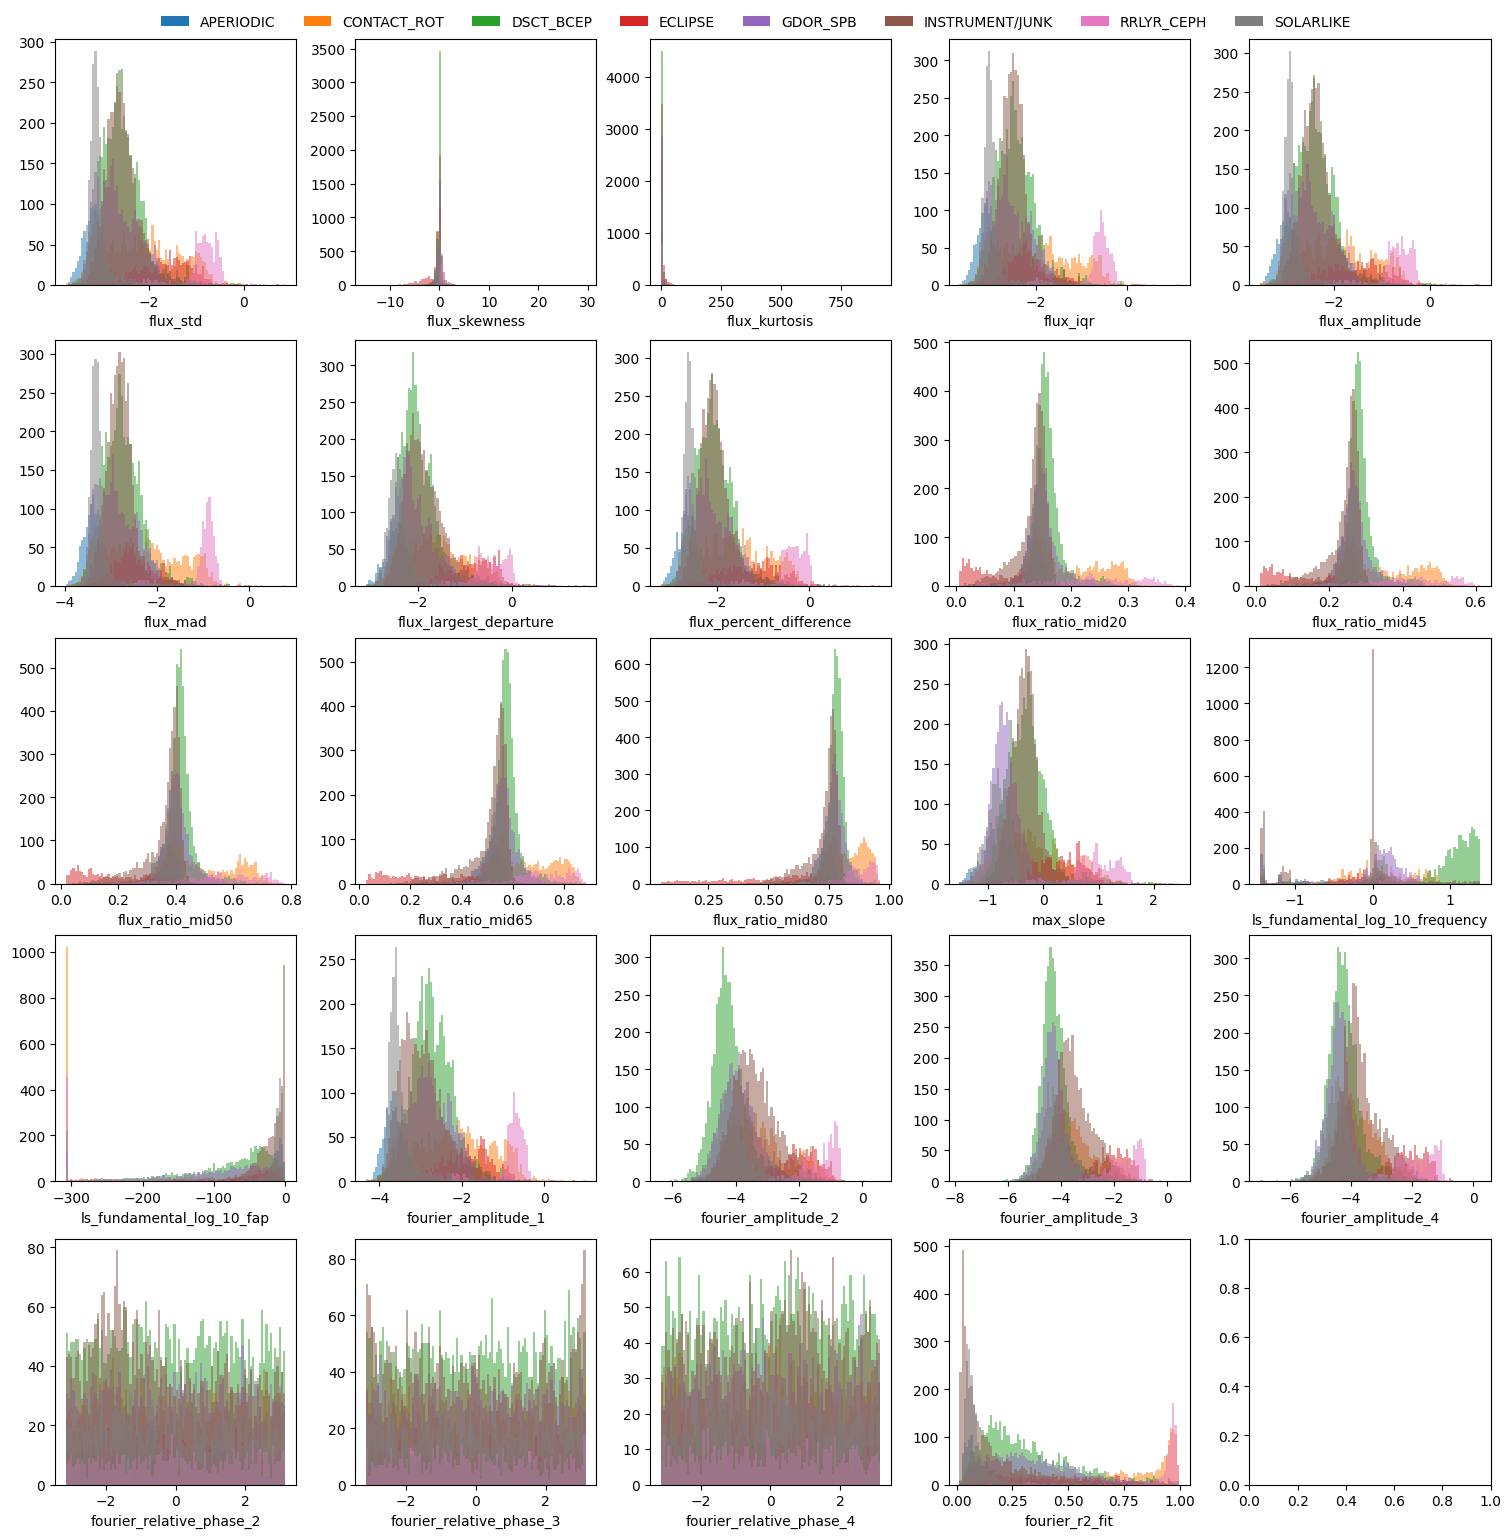

In [15]:
# Visualizing the features
bins = 100

fig, axs = plt.subplots(5, 5, figsize=(15, 15), constrained_layout=True)
for ax, col, col_name in zip(axs.ravel(), X_train.T, X_name):
    hrange = (np.amin(col), np.amax(col))
    for name in y_names:
        mask = y_train == name
        ax.hist(col[mask], range=hrange, bins=bins, label=name, alpha=0.5)
    ax.set_xlabel(col_name)

handles, labels = axs.ravel()[0].get_legend_handles_labels()
leg = fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02), frameon=False)
for h in leg.legend_handles:
    h.set_alpha(1.0)

## Classifiers

In [16]:
# Rescaling the features
from sklearn.preprocessing import QuantileTransformer, StandardScaler, RobustScaler

#rng = np.random.RandomState(0)
#qt = QuantileTransformer(n_quantiles=1000, random_state=0)
#X_train_prec3 = qt.fit_transform(X_train)
#X_prec1 = StandardScaler().fit_transform(X)
#X_prec2 = RobustScaler().fit_transform(X_train)
scaler = RobustScaler()
X_train_pre = scaler.fit_transform(X_train)
X_test_pre = scaler.transform(X_test)

In [17]:
# k-nn classifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV

clf = GridSearchCV(KNeighborsClassifier(n_jobs=4), cv=3, param_grid={'n_neighbors': [15, 25], 'weights': ['uniform', 'distance']}, scoring='f1_macro')
clf.fit(X_train_pre, y_train)
print(classification_report(y_true=y_test, y_pred=clf.predict(X_test_pre)))

                 precision    recall  f1-score   support

      APERIODIC       0.66      0.64      0.65       455
    CONTACT_ROT       0.84      0.51      0.63      1043
      DSCT_BCEP       0.94      0.90      0.92      2150
        ECLIPSE       0.92      0.84      0.88       381
       GDOR_SPB       0.80      0.72      0.76      1330
INSTRUMENT/JUNK       0.70      0.86      0.77      1664
     RRLYR_CEPH       0.96      0.91      0.93       316
      SOLARLIKE       0.51      0.75      0.61       715

       accuracy                           0.78      8054
      macro avg       0.79      0.77      0.77      8054
   weighted avg       0.80      0.78      0.78      8054



In [18]:
# Best hyperparameters 
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_n_neighbors,param_weights,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
i64,str,f64,f64,f64,f64,f64,i32
15,"""distance""",0.763585,0.767786,0.761194,0.764188,0.002725,1
15,"""uniform""",0.760881,0.765443,0.758849,0.761724,0.002757,2
25,"""distance""",0.757712,0.759022,0.758127,0.758287,0.000547,3
25,"""uniform""",0.755238,0.7565,0.757735,0.756491,0.001019,4


In [19]:
%%time

# Random Forest
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_jobs=4)
clf = GridSearchCV(RandomForestClassifier(n_jobs=4), cv=3, param_grid={
    'n_estimators': [50, 100, 200], 'class_weight': ['balanced', None], 'max_depth': [10, None]
}, scoring='f1_macro')

clf.fit(X_train_pre, y_train)
print(classification_report(y_true=y_test, y_pred=clf.predict(X_test_pre)))

                 precision    recall  f1-score   support

      APERIODIC       0.67      0.74      0.70       455
    CONTACT_ROT       0.83      0.71      0.76      1043
      DSCT_BCEP       0.97      0.93      0.95      2150
        ECLIPSE       0.96      0.86      0.91       381
       GDOR_SPB       0.87      0.81      0.84      1330
INSTRUMENT/JUNK       0.80      0.91      0.85      1664
     RRLYR_CEPH       0.97      0.95      0.96       316
      SOLARLIKE       0.68      0.77      0.72       715

       accuracy                           0.85      8054
      macro avg       0.84      0.84      0.84      8054
   weighted avg       0.86      0.85      0.85      8054

CPU times: user 3min 42s, sys: 769 ms, total: 3min 42s
Wall time: 1min 1s


In [20]:
# Best hyperparameters
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_class_weight,param_max_depth,param_n_estimators,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
str,object,i64,f64,f64,f64,f64,f64,i32
"""balanced""",null,200,0.832947,0.827078,0.837127,0.832384,0.004122,1
null,null,100,0.830414,0.828125,0.835432,0.831324,0.003052,2
"""balanced""",null,100,0.832872,0.824477,0.832988,0.830112,0.003985,3
null,null,200,0.827094,0.826442,0.831583,0.828373,0.002286,4
"""balanced""",null,50,0.830131,0.824394,0.827944,0.82749,0.002364,5
…,…,…,…,…,…,…,…,…
null,10,50,0.813256,0.808057,0.812077,0.81113,0.002225,8
"""balanced""",10,100,0.811077,0.805313,0.813851,0.810081,0.003556,9
null,10,100,0.814531,0.806159,0.808057,0.809582,0.003584,10


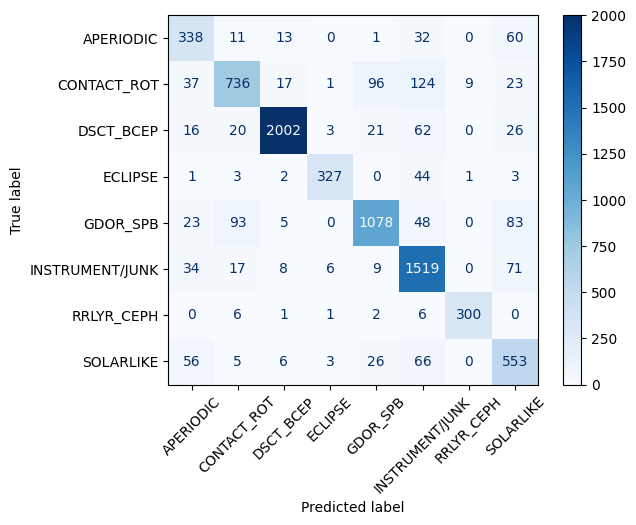

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_pred = clf.predict(X_test_pre)
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45)

## Error analysis

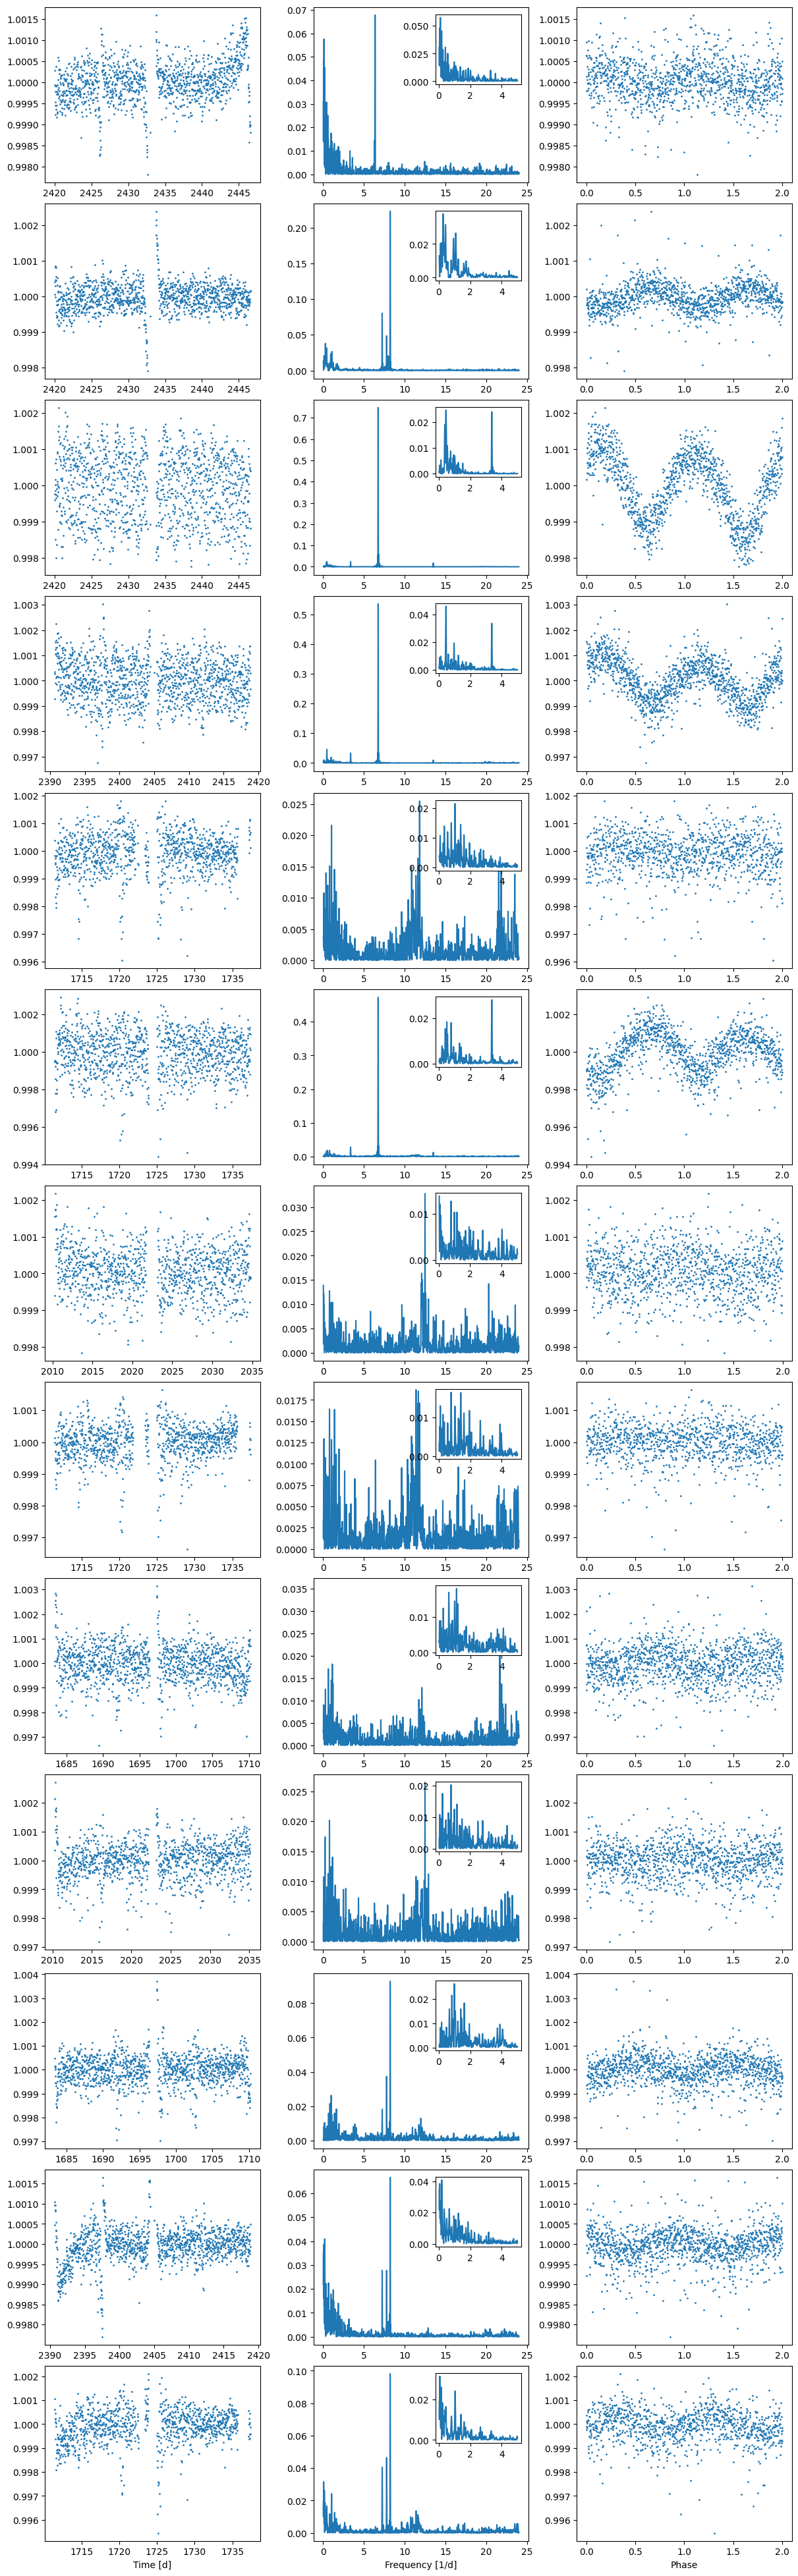

In [26]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from light_curves import read_fits_lc
from frequency_domain_features import compute_lombscargle_periodogram

#analysis_mask = (y_test == 'DSCT_BCEP') & (y_test_pred == 'ECLIPSE') # bad normalization and actual eclipse?
#analysis_mask = (y_test == 'DSCT_BCEP') & (y_test_pred == 'GDOR_SPB') # HYBRIDS AND GENUINE GDOR
#analysis_mask = (y_test == 'RRLYR_CEPH') & (y_test_pred == 'CONTACT_ROT') # Genuine rot or junk
#analysis_mask = (y_test == 'CONTACT_ROT') & (y_test_pred == 'RRLYR_CEPH') # Genuine rot (modulation) or junk
#analysis_mask = (y_test == 'CONTACT_ROT') & (y_test_pred == 'DSCT_BCEP') # junk and sinewaves with freq>5
analysis_mask = (y_test == 'APERIODIC') & (y_test_pred == 'DSCT_BCEP') # About half seem periodic!
#analysis_mask = (y_test == 'APERIODIC') & (y_test_pred == 'CONTACT_ROT') # Look aperiodic, bad classification
#analysis_mask = (y_test == 'RRLYR_CEPH') & (y_test_pred == 'GDOR_SPB') # Junk
#analysis_mask = (y_test == 'GDOR_SPB') & (y_test_pred == 'DSCT_BCEP') # Good GDOR or junk
analysis_path = path_test[analysis_mask]

fig, axs = plt.subplots(max(2, len(analysis_path)), 3, figsize=(12, 3*len(analysis_path)), constrained_layout=True, sharex=False)
for path_, ax in zip(analysis_path, axs):
    time, flux = read_fits_lc(path_, return_preprocessed=True)
    freq, ampl, _ = compute_lombscargle_periodogram(time, flux)
    best_freq = freq[np.argmax(ampl)]
    ax[0].scatter(time, flux, s=1)
    ax[1].plot(freq, ampl)
    ax[2].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1)
    axins = inset_axes(ax[1], width="40%", height="40%", loc="upper right", borderpad=0.8)
    axins.plot(freq[freq<5], ampl[freq<5])
ax[0].set_xlabel('Time [d]')
ax[1].set_xlabel('Frequency [1/d]')
ax[2].set_xlabel('Phase');

## Visualization of feature space

CPU times: user 2min 3s, sys: 916 ms, total: 2min 4s
Wall time: 43.5 s


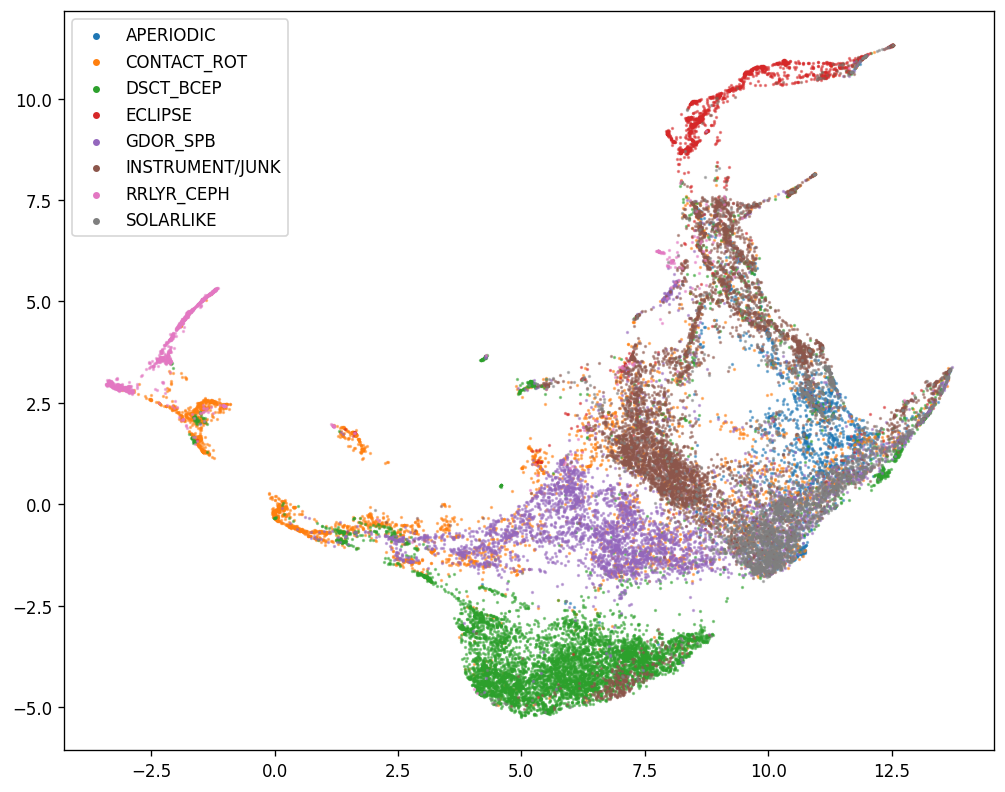

In [27]:
%%time
from umap import UMAP

projector = UMAP(n_components=2, min_dist=0.01, metric='euclidean', n_jobs=4, n_neighbors=25)
X_proj = projector.fit_transform(np.concatenate([X_train_pre, X_test_pre], axis=0))
y_proj = np.concatenate([y_train, y_test], axis=0)
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

for name in y_names:
    mask = y_proj == name
    ax.scatter(X_proj[mask, 0], X_proj[mask, 1], s=1, label=name, alpha=0.5)
leg = plt.legend()
for lh in leg.legend_handles:
    lh.set_alpha(1)
    lh._sizes = [10]

# Pathological cases

(array([], dtype=float64), array([], dtype=float64))

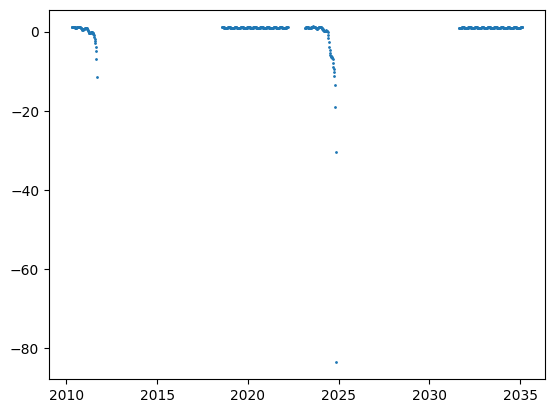

In [28]:
# Light curve completely filtered by outlier processing
from light_curves import read_fits_lc, remove_outliers

time, flux = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0026/cam1-ccd1/0020/9288/9154/7721/hlsp_tglc_tess_ffi_gaiaid-2092889154772199168-s0026-cam1-ccd1_tess_v1_llc.fits',
    return_preprocessed=False
)
plt.scatter(time, flux, s=1)
remove_outliers(time, flux, sigma_threshold=10)

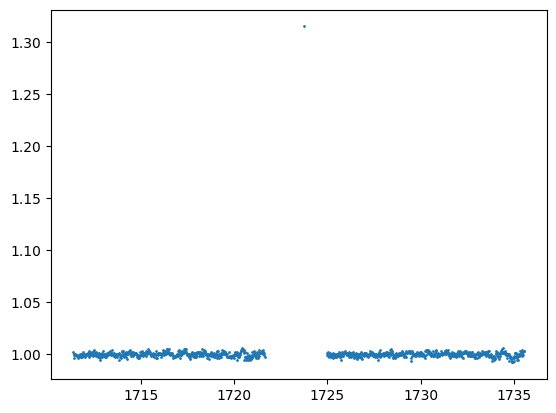

In [29]:
# Examples of extreme kurtosis

time, flux = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5667/2589/6237/hlsp_tglc_tess_ffi_gaiaid-1556672589623717632-s0015-cam4-ccd4_tess_v1_llc.fits',
    #'/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5697/4061/9678/hlsp_tglc_tess_ffi_gaiaid-1556974061967876096-s0015-cam4-ccd4_tess_v1_llc.fits',
    return_preprocessed=True
)
plt.scatter(time, flux, s=1)

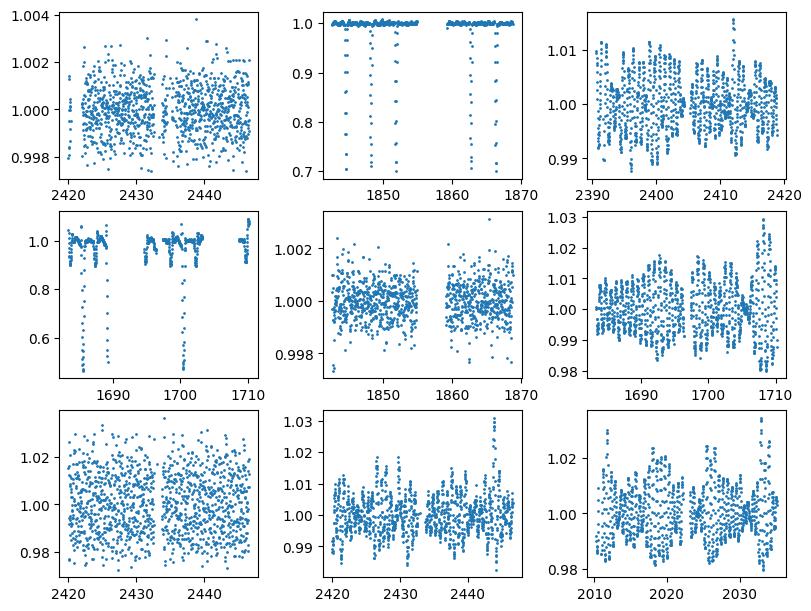

In [30]:
# Random light curves for reference of what is normal

fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
for path, ax in zip(df_training_features.sample(9)['path'].to_list(), axs.ravel()):
    time, flux = read_fits_lc(path, return_preprocessed=False)
    ax.scatter(time, flux, s=1)

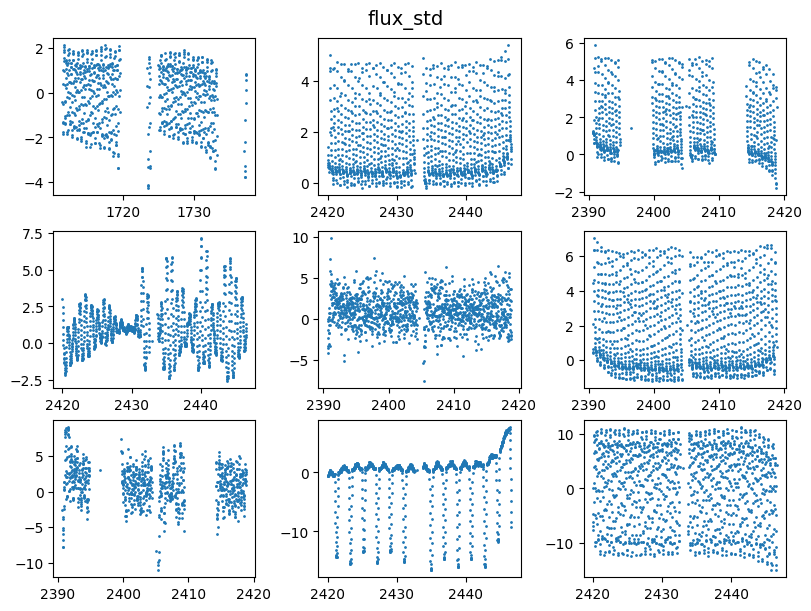

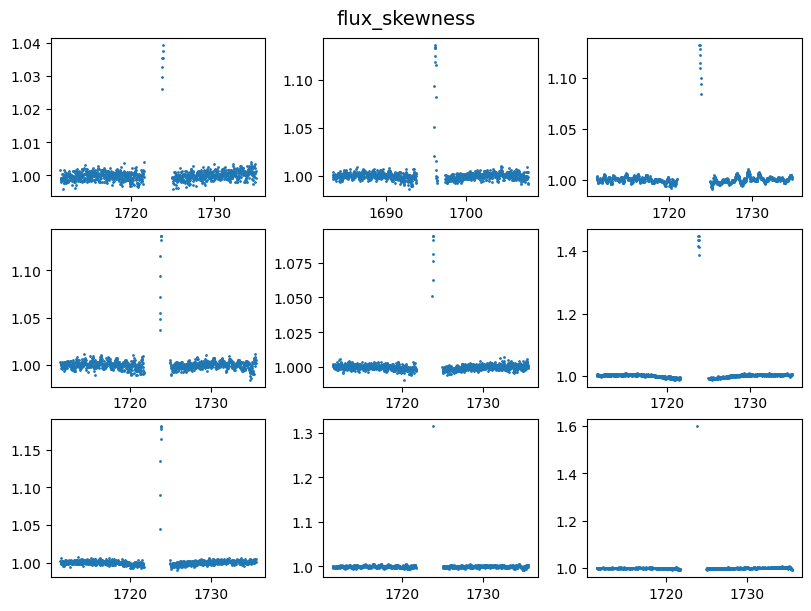

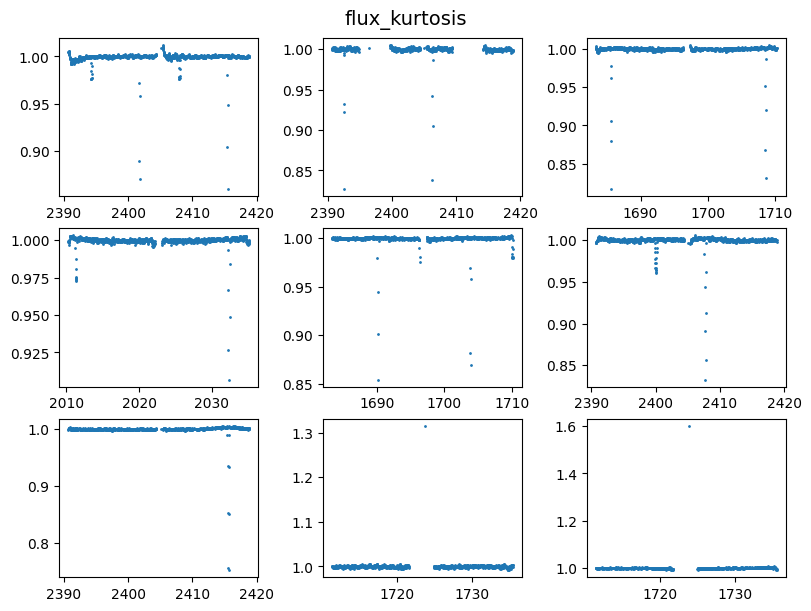

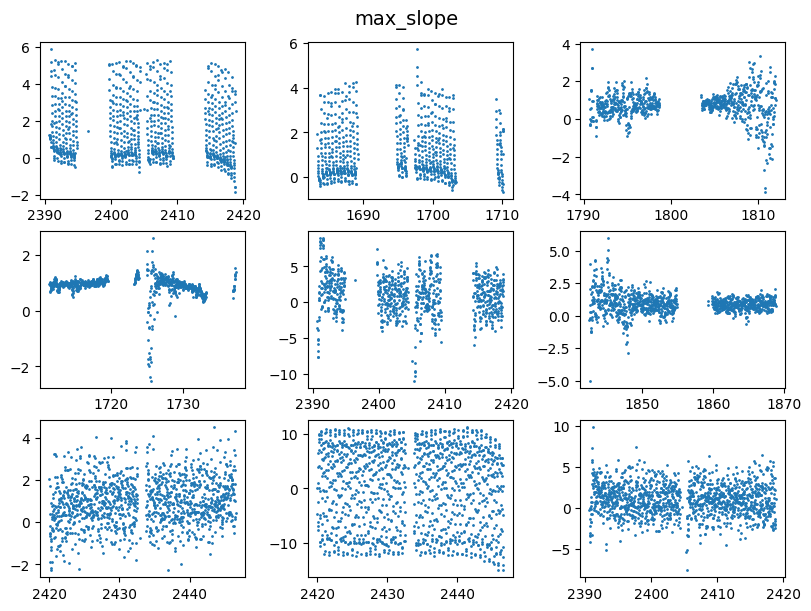

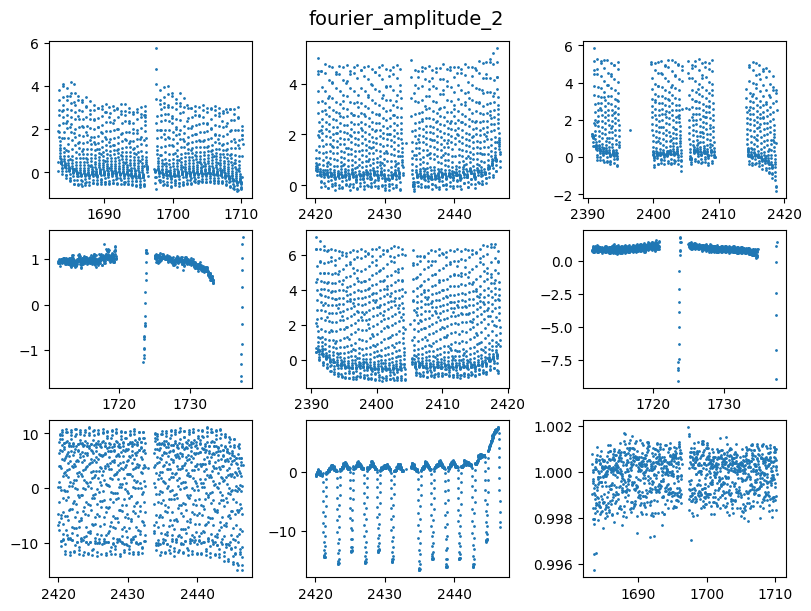

In [31]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).tail(9)['path'].to_list(), axs.ravel()):
        time, flux = read_fits_lc(path, return_preprocessed=True)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)

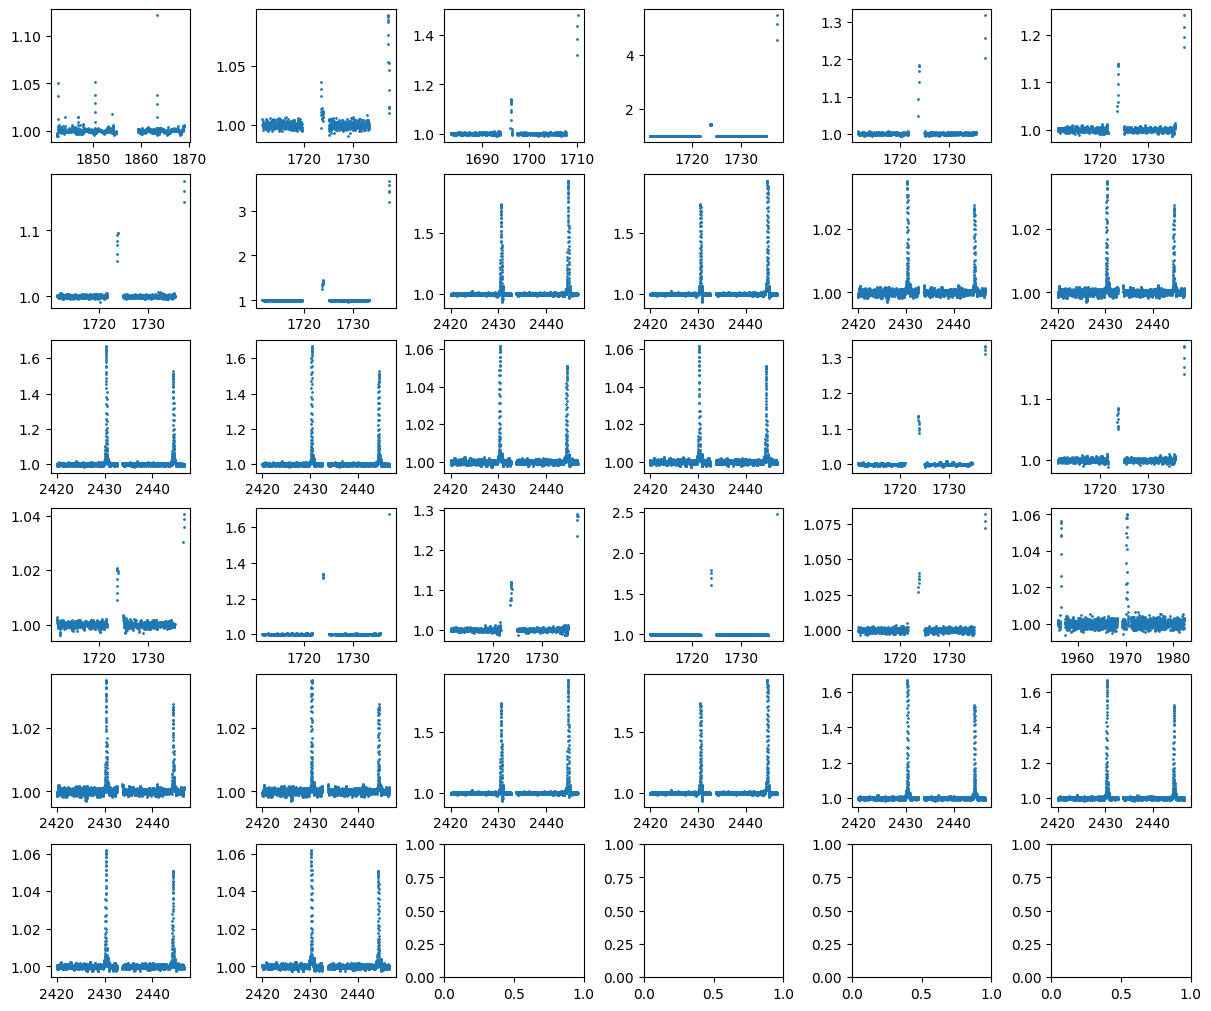

In [63]:
# Weird rise at the same time instants

fig, axs = plt.subplots(6, 6, figsize=(12, 10), constrained_layout=True)
for path, ax in zip(paths[np.where(X_proj[:, 0] > 15)[0]], axs.ravel()):
    time, flux = read_fits_lc(path, return_preprocessed=False)
    ax.scatter(time, flux, s=1)
#fig.suptitle(col, fontsize=14)

# Inference data

In [32]:
# Light curves per sector
total_rows = 0
for sector_parquet in sorted(list((plato_data_directory / 'paths').glob('*.parquet'))):
    n_rows = pl.scan_parquet(sector_parquet).select(pl.len()).collect().item()
    total_rows += n_rows
    print(sector_parquet.stem, f"{n_rows:_}".replace("_", " "))
print(f'Total: {total_rows:_}')

s0001 868 653
s0002 887 052
s0003 876 167
s0004 1 003 670
s0005 1 330 890
s0006 1 796 254
s0007 2 738 813
s0008 701 061
s0009 2 318 432
s0010 1 525 939
s0011 938 662
s0012 853 122
s0013 857 136
s0027 862 707
s0028 873 037
s0029 894 534
s0030 964 270
s0031 1 151 634
s0032 1 508 806
s0033 2 561 595
s0034 3 723 449
s0035 3 119 952
s0036 2 098 609
s0037 1 346 670
s0038 894 792
s0039 828 936
Total: 37_524_842


In [33]:
index = pl.scan_parquet(sector_parquet).head(5).collect().to_series().to_list()
index

['/STER/mamsie/tess/TIC/plato_fov/s0039/cam4-ccd2/0052/7917/2800/0735/hlsp_tglc_tess_ffi_gaiaid-5279172800073566464-s0039-cam4-ccd2_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0039/cam4-ccd2/0052/7917/0562/3926/hlsp_tglc_tess_ffi_gaiaid-5279170562392697216-s0039-cam4-ccd2_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0039/cam4-ccd2/0052/7917/5132/2482/hlsp_tglc_tess_ffi_gaiaid-5279175132248243968-s0039-cam4-ccd2_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0039/cam4-ccd2/0052/7917/9259/7044/hlsp_tglc_tess_ffi_gaiaid-5279179259704411008-s0039-cam4-ccd2_tess_v1_llc.fits',
 '/STER/mamsie/tess/TIC/plato_fov/s0039/cam4-ccd2/0052/7917/0356/2336/hlsp_tglc_tess_ffi_gaiaid-5279170356233676032-s0039-cam4-ccd2_tess_v1_llc.fits']

In [34]:
# Example of feature extraction

from feature_extractors import extract_features_from_path

extract_features_from_path(index[0])

{'flux_std': 0.0030058213730538184,
 'flux_skewness': -0.27466562120668153,
 'flux_kurtosis': 0.13580368172276902,
 'flux_iqr': 0.00401954333875687,
 'flux_amplitude': 0.004914565158930795,
 'flux_mad': 0.0020129053818891407,
 'flux_largest_departure': 0.010190116275432811,
 'flux_percent_difference': 0.009829535725294474,
 'flux_ratio_mid20': 0.1583295991973512,
 'flux_ratio_mid45': 0.27257161805945157,
 'flux_ratio_mid50': 0.40894191131564483,
 'flux_ratio_mid65': 0.5510454515423385,
 'flux_ratio_mid80': 0.7824359529109923,
 'max_slope': 0.5397174794288797,
 'ls_fundamental_log_10_frequency': -0.02679374338269566,
 'ls_fundamental_log_10_fap': -1.9139287097662836,
 'fourier_amplitude_1': 0.0005840161218063503,
 'fourier_amplitude_2': 0.00018525491606195599,
 'fourier_amplitude_3': 5.83775893592525e-05,
 'fourier_amplitude_4': 0.0003636905989000829,
 'fourier_relative_phase_2': 2.4085242330792536,
 'fourier_relative_phase_3': 1.601445367770502,
 'fourier_relative_phase_4': -1.41139052

In [35]:
%%time
# Example of feature extraction in parallel
from feature_extractors import extract_features_parallel

extract_features_parallel(index, n_jobs=1, backend='loky', worker_batch_size=5)

CPU times: user 617 ms, sys: 55 μs, total: 617 ms
Wall time: 664 ms


[{'flux_std': 0.0030058213730538184,
  'flux_skewness': -0.27466562120668153,
  'flux_kurtosis': 0.13580368172276902,
  'flux_iqr': 0.00401954333875687,
  'flux_amplitude': 0.004914565158930795,
  'flux_mad': 0.0020129053818891407,
  'flux_largest_departure': 0.010190116275432811,
  'flux_percent_difference': 0.009829535725294474,
  'flux_ratio_mid20': 0.1583295991973512,
  'flux_ratio_mid45': 0.27257161805945157,
  'flux_ratio_mid50': 0.40894191131564483,
  'flux_ratio_mid65': 0.5510454515423385,
  'flux_ratio_mid80': 0.7824359529109923,
  'max_slope': 0.5397174794288797,
  'ls_fundamental_log_10_frequency': -0.02679374338269566,
  'ls_fundamental_log_10_fap': -1.9139287097662836,
  'fourier_amplitude_1': 0.0005840161218063503,
  'fourier_amplitude_2': 0.00018525491606195599,
  'fourier_amplitude_3': 5.83775893592525e-05,
  'fourier_amplitude_4': 0.0003636905989000829,
  'fourier_relative_phase_2': 2.4085242330792536,
  'fourier_relative_phase_3': 1.601445367770502,
  'fourier_relativ